Take an arbitrary DNA sequence from NCBI (bacterial genome).  Use 5 restriction enzymes (name, recognized site and cleaveage site).

        5'GAATTC        5'---G      AATTC---3'
EcoRi   3'CTTAAG        3'---CTTAA  G---5'

        5'GGATCC        5'---G      GATCC---3'
BamHI   3'CCTAGG        3'---CCTAG  G---5'

        5'AAGCTT        5'---A      AGCTT---3'
HimdIII 3'TTCGAA        3'---TTCGA  A---5'

        5'TCGA          5'---T      CGA---3'
TaqI    3'AGCT          3'---AGC    T---5'

        5'GGCC          5'---GG     CC---3'
HaeIII* 3'CCGG          3'---CC     GG---5'

Input of the implementation:
1. The recognized sequence for each restriction enzyme.
2. The DNA sequence to be digested.

Output of the implementation:
1. Number of cleaveages ofr each restriction enzyme.
2. Cleaveage positions and length of fragments.
A simulation of the electrophoresis gen based on the number of restriction enzymes used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

ENZYMES = {
    "EcoRI":   ("GAATTC", 1),   # G^AATTC
    "BamHI":   ("GGATCC", 1),   # G^GATCC
    "HindIII": ("AAGCTT", 1),   # A^AGCTT
    "TaqI":    ("TCGA",   1),   # T^CGA
    "HaeIII":  ("GGCC",   2),   # GG^CC (blunt)
}

def read_fasta(path):
    with open(path) as f:
        lines = f.read().splitlines()
    return "".join(l.strip() for l in lines if not l.startswith(">")).upper()

dna = read_fasta("ecoli_cft073.fasta")
print("Genome length:", len(dna), "bp")

Genome length: 5231428 bp


In [2]:
def revcomp(s):
    return s.translate(str.maketrans("ACGT", "TGCA"))[::-1]

def find_cuts(dna, site, offset):
    """0-based cut positions (a cut at p means between dna[p-1] and dna[p]).
    Also scans the reverse strand for non-palindromic sites (not needed here, but safe)."""
    cuts, i = [], dna.find(site)
    while i != -1:
        cuts.append(i + offset)
        i = dna.find(site, i + 1)      # allows overlapping matches
    rc = revcomp(site)
    if rc != site:
        i = dna.find(rc)
        while i != -1:
            cuts.append(i + len(site) - offset)
            i = dna.find(rc, i + 1)
    return sorted(set(cuts))

def fragments(cuts, n):
    bounds = [0] + cuts + [n]
    return [bounds[i+1] - bounds[i] for i in range(len(bounds) - 1)]

results = {}
for name, (site, off) in ENZYMES.items():
    cuts = find_cuts(dna, site, off)
    frags = fragments(cuts, len(dna))
    results[name] = (cuts, frags)
    print(f"{name} ({site}): {len(cuts)} cleavages -> {len(frags)} fragments")

EcoRI (GAATTC): 743 cleavages -> 744 fragments
BamHI (GGATCC): 560 cleavages -> 561 fragments
HindIII (AAGCTT): 607 cleavages -> 608 fragments
TaqI (TCGA): 16487 cleavages -> 16488 fragments
HaeIII (GGCC): 14023 cleavages -> 14024 fragments


In [3]:
for name, (cuts, frags) in results.items():
    print(f"\n=== {name} ===  cleavages: {len(cuts)}")
    if len(cuts) <= 15:
        print("cut positions:", cuts)
        print("fragment lengths:", frags)
    else:
        print("first 10 cut positions:", cuts[:10], "...")
        print("fragment lengths (10 largest):", sorted(frags, reverse=True)[:10], "...")
        print(f"fragment lengths: min={min(frags)}, max={max(frags)}, mean={np.mean(frags):.0f}")


=== EcoRI ===  cleavages: 743
first 10 cut positions: [4553, 13672, 14008, 18020, 18755, 34902, 35172, 39044, 47294, 52868] ...
fragment lengths (10 largest): [53210, 40327, 39267, 38840, 34669, 34039, 33740, 33547, 30776, 30533] ...
fragment lengths: min=20, max=53210, mean=7031

=== BamHI ===  cleavages: 560
first 10 cut positions: [9716, 25980, 40171, 43505, 47191, 56900, 69522, 72631, 79989, 91000] ...
fragment lengths (10 largest): [67825, 59233, 48435, 46716, 41729, 40753, 39989, 39590, 39584, 36867] ...
fragment lengths: min=21, max=67825, mean=9325

=== HindIII ===  cleavages: 607
first 10 cut positions: [348, 6348, 9530, 15105, 15988, 67669, 74878, 81972, 87293, 91571] ...
fragment lengths (10 largest): [86234, 78303, 68054, 59687, 51681, 48493, 47891, 45236, 41789, 41068] ...
fragment lengths: min=9, max=86234, mean=8604

=== TaqI ===  cleavages: 16487
first 10 cut positions: [787, 870, 1021, 1328, 1435, 1490, 1499, 1529, 1789, 2444] ...
fragment lengths (10 largest): [4588,

### Electrophoresis simulation
Agarose gel window fixed to 100-10,000 bp to match the ladder. Migration is linear in log10(size). Band intensity is DNA mass (length) per position, summed over all fragments and blurred, so many close-sized fragments form a smear instead of overlapping bars. Fragments below 100 bp run off the gel; those above 10,000 bp are compressed together at the top.

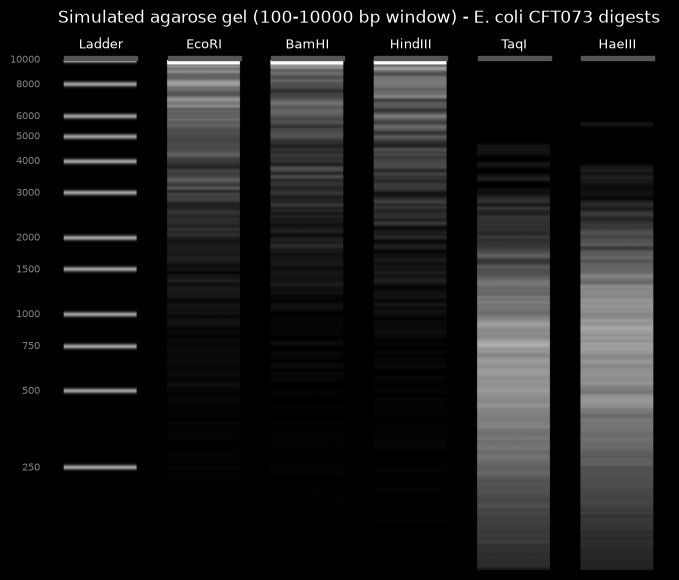

EcoRI: 10 fragments < 100 bp ran off, 181 fragments > 10000 bp compressed at top
BamHI: 7 fragments < 100 bp ran off, 186 fragments > 10000 bp compressed at top
HindIII: 14 fragments < 100 bp ran off, 175 fragments > 10000 bp compressed at top
TaqI: 4783 fragments < 100 bp ran off, 0 fragments > 10000 bp compressed at top
HaeIII: 3393 fragments < 100 bp ran off, 0 fragments > 10000 bp compressed at top


In [ ]:
ladder = [10000, 8000, 6000, 5000, 4000, 3000, 2000, 1500, 1000, 750, 500, 250]
from scipy.ndimage import gaussian_filter1d

# Fixed gel range matched to the ladder: fragments < MIN_BP ran off the gel,
# fragments > MAX_BP are compressed together at the top of the resolving zone.
MIN_BP, MAX_BP = 100, 10000
ROWS = 700

def migration(size):
    """0 = top of gel (large), 1 = bottom (small); linear in log10(size)."""
    s = np.clip(size, MIN_BP, MAX_BP)
    return (np.log10(MAX_BP) - np.log10(s)) / (np.log10(MAX_BP) - np.log10(MIN_BP))

def lane_profile(sizes, sigma=2.0):
    """Band intensity along the lane = DNA mass (length) per pixel row, blurred a bit."""
    sizes = np.asarray(sizes, dtype=float)
    sizes_in = sizes[sizes >= MIN_BP]
    rows = (migration(sizes_in) * (ROWS - 1)).astype(int)
    prof = np.bincount(rows, weights=sizes_in, minlength=ROWS).astype(float)
    return gaussian_filter1d(prof, sigma)

ladder_profile = np.zeros(ROWS)
for s in ladder:
    ladder_profile[int(migration(s) * (ROWS - 1))] += 1.0
ladder_profile = gaussian_filter1d(ladder_profile, 2.0)
ladder_profile /= ladder_profile.max()

profiles = {name: lane_profile(f) for name, (_, f) in results.items()}
gain = 1.0 / np.percentile(np.concatenate(list(profiles.values())), 99.5)

lane_w = 60
gap = 25
names = ["Ladder"] + list(profiles)
img = np.zeros((ROWS, len(names) * (lane_w + gap)))
for i, name in enumerate(names):
    p = ladder_profile if name == "Ladder" else np.clip(profiles[name] * gain, 0, 1)
    x0 = i * (lane_w + gap) + gap // 2
    img[:, x0:x0 + lane_w] = p[:, None]
img = img ** 0.7

fig, ax = plt.subplots(figsize=(8, 7), facecolor="black")
ax.imshow(img, cmap="gray", aspect="auto", vmin=0, vmax=1, interpolation="bilinear")
for i, name in enumerate(names):
    ax.text(i * (lane_w + gap) + gap // 2 + lane_w / 2, -12, name, color="white", ha="center", va="bottom", fontsize=9)
    ax.add_patch(plt.Rectangle((i * (lane_w + gap) + gap // 2, -6), lane_w, 6, color="#555"))   # well
for s in ladder:
    ax.text(-8, migration(s) * (ROWS - 1), f"{s}", color="gray", ha="right", va="center", fontsize=7)
ax.set_ylim(ROWS, -40)
ax.axis("off")
ax.set_title(f"Simulated agarose gel ({MIN_BP}-{MAX_BP} bp window) - E. coli CFT073 digests", color="white")
plt.show()

for name, (_, f) in results.items():
    f = np.array(f)
    print(f"{name}: {np.sum(f < MIN_BP)} fragments < {MIN_BP} bp ran off, {np.sum(f > MAX_BP)} fragments > {MAX_BP} bp compressed at top")